# 🪃 NexusReturnGuard — 01 EDA
**NEXUS OptiML 2026 — Operation Insight**

**Goal:** Predict probability that an order line is returned.
**Metric:** ROC-AUC (ranking only)
**Split:** Train = months 1–24, Test = months 25–30 (future)

## Phase 1 Roadmap
1. Load files + shapes
2. Dtypes + memory downcast
3. Target + imbalance + monthly drift
4. Train vs test (cold-start check)
5. Missing values
6. Duplicates
7. Messy labels
8. Timestamps
9. Return rate by segment

**Output:** only notes. No saved data. Cleaning comes in NB2.

## Task 1: Load files + shapes
**Why:** Know what data we have. Verify row counts match competition page.
**Check:** train 1,400,005 | test 479,995 | cust 204,930 | prod 48,677 | store 454 | cal 132
**Look for:** target column only in train, column names for later joins.

In [1]:
import pandas as pd, numpy as np
import warnings; warnings.filterwarnings('ignore')

p = '/kaggle/input/competitions/nexus-opti-ml-2026-operation-insight/'

tr  = pd.read_csv(p + 'train.csv')
te  = pd.read_csv(p + 'test.csv')
sub = pd.read_csv(p + 'sample_submission.csv')
cu  = pd.read_csv(p + 'customers.csv')
pr  = pd.read_csv(p + 'products.csv')
st  = pd.read_csv(p + 'stores.csv')
ca  = pd.read_csv(p + 'calendar.csv')

dfs = {'train': tr, 'test': te, 'sub': sub, 'cust': cu,
       'prod': pr, 'store': st, 'cal': ca}

for name, d in dfs.items():
    mem = d.memory_usage(deep=True).sum() / 1e6
    print(f"{name:6} shape={d.shape}  mem={mem:.0f} MB")
    print("   cols:", d.columns.tolist())

train  shape=(1400005, 27)  mem=1296 MB
   cols: ['order_line_id', 'order_id', 'customer_id', 'product_id', 'store_id', 'order_ts', 'tz_hint', 'channel', 'payment_method', 'ship_mode', 'unit_price', 'quantity', 'discount', 'freight_cost', 'order_value', 'line_no', 'items_in_order', 'gift_wrap', 'promo_channel_code', 'return_window_days', 'warehouse_zone', 'picker_shift', 'banner_id', 'session_clicks', 'device_type', 'coupon_code', 'returned']
test   shape=(479995, 26)  mem=441 MB
   cols: ['order_line_id', 'order_id', 'customer_id', 'product_id', 'store_id', 'order_ts', 'tz_hint', 'channel', 'payment_method', 'ship_mode', 'unit_price', 'quantity', 'discount', 'freight_cost', 'order_value', 'line_no', 'items_in_order', 'gift_wrap', 'promo_channel_code', 'return_window_days', 'warehouse_zone', 'picker_shift', 'banner_id', 'session_clicks', 'device_type', 'coupon_code']
sub    shape=(479995, 2)  mem=35 MB
   cols: ['order_line_id', 'returned']
cust   shape=(204930, 9)  mem=96 MB
   cols: 

## Task 2: Dtypes + memory downcast
**Why:** Train is 354 MB. Smaller types = less RAM, faster work.
**Do:** float64→float32, int64→int32/int16, object→category.
**Check:** memory before vs after.

In [2]:
# 1. See dtypes of train
print(tr.dtypes)

# 2. Downcast function
def downcast(df):
    for c in df.columns:
        t = df[c].dtype
        if t == 'float64':
            df[c] = df[c].astype('float32')
        elif t == 'int64':
            df[c] = pd.to_numeric(df[c], downcast='integer')
        elif t == 'object':
            # skip id + date cols, convert only low-cardinality text
            if df[c].nunique() / len(df) < 0.5 and not c.endswith(('_id', '_ts', '_date', '_at')) and c != 'week_start':
                df[c] = df[c].astype('category')
    return df

# 3. Memory before
before = sum(d.memory_usage(deep=True).sum() for d in dfs.values()) / 1e6

# 4. Apply
for name in ['train', 'test', 'cust', 'prod', 'store', 'cal']:
    dfs[name] = downcast(dfs[name])

tr, te, cu, pr, st, ca = (dfs[k] for k in ['train','test','cust','prod','store','cal'])

# 5. Memory after
after = sum(d.memory_usage(deep=True).sum() for d in dfs.values()) / 1e6
print(f"Memory: {before:.0f} MB -> {after:.0f} MB")

# 6. Check new dtypes
print(tr.dtypes)

order_line_id          object
order_id               object
customer_id            object
product_id             object
store_id               object
order_ts               object
tz_hint                object
channel                object
payment_method         object
ship_mode              object
unit_price            float64
quantity                int64
discount              float64
freight_cost          float64
order_value           float64
line_no                 int64
items_in_order          int64
gift_wrap               int64
promo_channel_code     object
return_window_days      int64
warehouse_zone         object
picker_shift           object
banner_id               int64
session_clicks        float64
device_type            object
coupon_code            object
returned                int64
dtype: object
Memory: 1886 MB -> 861 MB
order_line_id           object
order_id                object
customer_id             object
product_id              object
store_id                ob

## Task 3: Target, imbalance, monthly drift
**Why:** Imbalance decides if we need class weights. Drift shows if return rate changes over time (test is future).
**Do:** `returned` ratio + return rate per month.
**Look for:** rate stable or trending? Big jump = danger for validation.

returned
0    1147268
1     252737
Name: count, dtype: int64
returned
0    0.8195
1    0.1805
Name: proportion, dtype: float64
Positive ratio: 0.1805
Unparsed train: 0 | test: 0
Train range: 2022-12-31 16:01:00+00:00 -> 2025-01-01 02:47:00+00:00
Test  range: 2024-12-31 17:31:00+00:00 -> 2025-07-01 23:31:00+00:00
             mean  count
ym                      
2022-12  0.200000     20
2023-01  0.179641  66978
2023-02  0.179134  40467
2023-03  0.177854  52740
2023-04  0.182743  51318
2023-05  0.179644  54402
2023-06  0.179942  51400
2023-07  0.178275  56699
2023-08  0.181187  58067
2023-09  0.179897  54359
2023-10  0.180059  53860
2023-11  0.183894  54602
2023-12  0.179264  56849
2024-01  0.181619  70389
2024-02  0.179991  70370
2024-03  0.181352  91044
2024-04  0.181087  58204
2024-05  0.179392  54105
2024-06  0.180046  52209
2024-07  0.180520  59589
2024-08  0.181400  58214
2024-09  0.180378  55090
2024-10  0.183487  61345
2024-11  0.178797  58821
2024-12  0.181784  58850
2025-01  0.

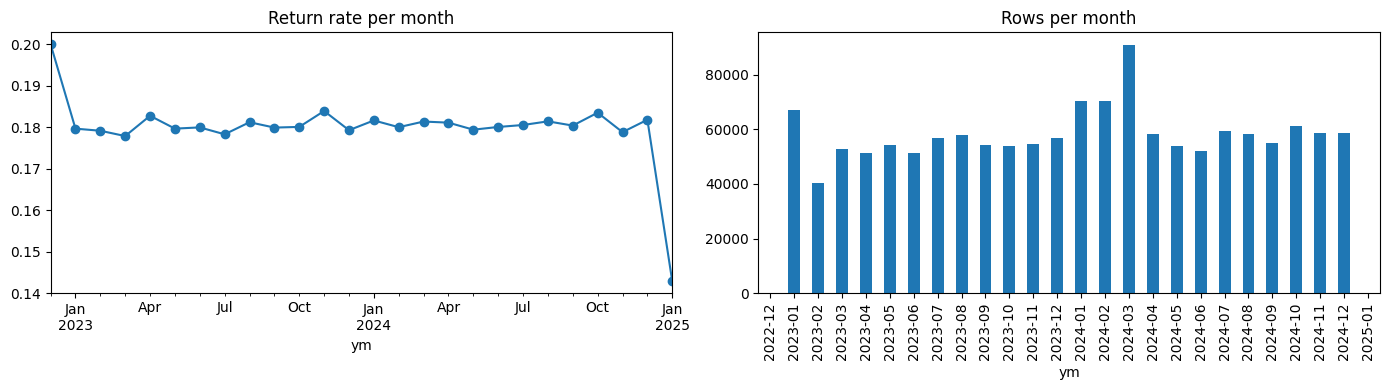

In [3]:
import matplotlib.pyplot as plt

# 1. Imbalance
print(tr['returned'].value_counts())
print(tr['returned'].value_counts(normalize=True).round(4))
print("Positive ratio:", round(tr['returned'].mean(), 4))

# 2. Rough timestamp parse (proper fix in Task 8)
tr['ts'] = pd.to_datetime(tr['order_ts'], errors='coerce', utc=True, format='mixed')
te['ts'] = pd.to_datetime(te['order_ts'], errors='coerce', utc=True, format='mixed')
print("Unparsed train:", tr['ts'].isna().sum(), "| test:", te['ts'].isna().sum())
print("Train range:", tr['ts'].min(), "->", tr['ts'].max())
print("Test  range:", te['ts'].min(), "->", te['ts'].max())

# 3. Monthly drift
tr['ym'] = tr['ts'].dt.tz_localize(None).dt.to_period('M')
m = tr.groupby('ym')['returned'].agg(['mean', 'count'])
print(m)

# 4. Plot
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
m['mean'].plot(ax=ax[0], marker='o', title='Return rate per month')
m['count'].plot(ax=ax[1], kind='bar', title='Rows per month')
plt.tight_layout(); plt.show()

## Task 4: Train vs test + cold-start
**Why:** Test is future period. New customers/products/stores unseen in train can't use history features.
**Do:** % of test ids not in train. Compare numeric distributions.
**Look for:** high unseen % → rely less on id target encoding.

In [4]:
# 1. Cold-start: test ids unseen in train
for k in ['customer_id', 'product_id', 'store_id', 'order_id']:
    unseen = (~te[k].isin(set(tr[k]))).mean()
    print(f"{k:12} test unseen in train: {unseen:.2%} | nunique train={tr[k].nunique()} test={te[k].nunique()}")

# 2. Orphan keys: ids missing from master tables
for k, master in [('customer_id', cu), ('product_id', pr), ('store_id', st)]:
    print(f"{k:12} train not in master: {(~tr[k].isin(set(master[k]))).mean():.2%} | test: {(~te[k].isin(set(master[k]))).mean():.2%}")

# 3. Numeric shift
num = ['unit_price','quantity','discount','freight_cost','order_value',
       'items_in_order','session_clicks','return_window_days']
cmp = pd.DataFrame({'train_mean': tr[num].mean(), 'test_mean': te[num].mean(),
                    'train_med': tr[num].median(), 'test_med': te[num].median()})
cmp['ratio_mean'] = cmp['test_mean'] / cmp['train_mean']
print(cmp.round(3))

# 4. Categorical shift (top 5 biggest diffs per column)
cats = ['channel','payment_method','ship_mode','device_type','warehouse_zone','picker_shift','tz_hint']
for c in cats:
    d = pd.concat([tr[c].value_counts(normalize=True).rename('train'),
                   te[c].value_counts(normalize=True).rename('test')], axis=1).fillna(0)
    d['diff'] = (d['test'] - d['train']).abs()
    print(f"\n{c}"); print(d.sort_values('diff', ascending=False).head(5).round(3))

# 5. Test rows per month
print(te.groupby(te['ts'].dt.tz_localize(None).dt.to_period('M')).size())

customer_id  test unseen in train: 12.26% | nunique train=172468 test=83807
product_id   test unseen in train: 0.18% | nunique train=47868 test=43586
store_id     test unseen in train: 0.00% | nunique train=452 test=453
order_id     test unseen in train: 100.00% | nunique train=444024 test=151459
customer_id  train not in master: 0.00% | test: 0.00%
product_id   train not in master: 0.00% | test: 0.00%
store_id     train not in master: 0.00% | test: 0.00%
                    train_mean  test_mean  train_med  test_med  ratio_mean
unit_price              58.101     57.077       6.30      6.16       0.982
quantity                49.536     49.603       5.00      5.00       1.001
discount                 0.268      0.274       0.16      0.17       1.024
freight_cost            13.676     13.811       9.18      9.40       1.010
order_value            614.188    604.778      34.00     34.00       0.985
items_in_order          41.426     52.732       5.00      5.00       1.273
session_clicks 

## Task 5: Missing values
**Why:** Missingness may itself predict returns. Decides fill strategy.
**Do:** % missing per column, all tables. Check return rate when missing vs not.
**Look for:** columns >50% missing, missing-vs-target gap.

In [5]:
# 1. Missing % per table
for name, d in [('train', tr), ('test', te), ('cust', cu), ('prod', pr), ('store', st), ('cal', ca)]:
    miss = (d.isna().mean() * 100).round(2)
    miss = miss[miss > 0].sort_values(ascending=False)
    print(f"\n{name}: {len(miss)} cols with missing")
    if len(miss): print(miss.to_string())

# 2. Missing vs target (train only)
rows = []
for c in tr.columns.drop(['returned', 'ts', 'ym']):
    n = tr[c].isna().mean()
    if n > 0:
        rate_miss = tr.loc[tr[c].isna(), 'returned'].mean()
        rate_ok = tr.loc[tr[c].notna(), 'returned'].mean()
        rows.append((c, round(n*100, 2), round(rate_miss, 4), round(rate_ok, 4), round(rate_miss - rate_ok, 4)))
print("\ncol | miss% | rate_when_missing | rate_when_present | gap")
for r in sorted(rows, key=lambda x: -abs(x[4])): print(r)

# 3. Sentinel / fake-missing values in text cols
junk = ['', ' ', '?', 'unknown', 'Unknown', 'UNKNOWN', 'n/a', 'N/A', 'na', 'NA', 'none', 'None', 'null', 'NULL', '-', 'nan']
for name, d in [('train', tr), ('cust', cu), ('prod', pr), ('store', st)]:
    for c in d.select_dtypes(['object', 'category']).columns:
        cnt = d[c].astype(str).isin(junk).sum()
        if cnt > 0: print(f"{name}.{c}: {cnt} junk values")

# 4. Weird numerics (negative, zero)
for c in ['unit_price', 'quantity', 'discount', 'freight_cost', 'order_value', 'session_clicks']:
    print(f"{c:15} neg={(tr[c] < 0).sum():>7}  zero={(tr[c] == 0).sum():>7}  max={tr[c].max():.1f}  p99={tr[c].quantile(.99):.1f}")


train: 7 cols with missing
coupon_code       88.12
tz_hint           20.02
session_clicks     7.41
freight_cost       4.05
ship_mode          4.03
discount           3.06
payment_method     3.01

test: 7 cols with missing
coupon_code       87.99
tz_hint           19.92
session_clicks     7.49
freight_cost       4.08
ship_mode          4.01
discount           3.05
payment_method     3.01

cust: 1 cols with missing
age_band    7.97

prod: 1 cols with missing
weight_kg    4.28

store: 1 cols with missing
size_sqm    76.65

cal: 0 cols with missing

col | miss% | rate_when_missing | rate_when_present | gap
('session_clicks', np.float64(7.41), np.float64(0.2007), np.float64(0.1789), np.float64(0.0217))
('freight_cost', np.float64(4.05), np.float64(0.191), np.float64(0.1801), np.float64(0.011))
('discount', np.float64(3.06), np.float64(0.1862), np.float64(0.1803), np.float64(0.0059))
('ship_mode', np.float64(4.03), np.float64(0.1823), np.float64(0.1805), np.float64(0.0018))
('payment_method

## Task 6: Duplicates
**Why:** Duplicate customers explode row count on merge. Duplicate order lines = bad labels.
**Do:** dup `order_line_id`, dup `customer_id`, dup product/store ids.
**Look for:** how to dedupe (keep latest? most complete?).

In [6]:
# 1. Duplicate order lines
print("dup order_line_id  train:", tr['order_line_id'].duplicated().sum(), "| test:", te['order_line_id'].duplicated().sum())
print("test ids match sample_submission:", set(te['order_line_id']) == set(sub['order_line_id']))
print("order_line_id overlap train/test:", len(set(tr['order_line_id']) & set(te['order_line_id'])))

# 2. Duplicate rows ignoring order_line_id (same order repeated?)
cols = [c for c in tr.columns if c not in ['order_line_id', 'ts', 'ym']]
dup_mask = tr.duplicated(subset=cols, keep=False)
print("\nrows identical except line id:", dup_mask.sum(), f"({dup_mask.mean():.2%})")

# FIXED: Wrapped both .mean() calls inside round(..., 4)
mean_dup = round(tr.loc[dup_mask, 'returned'].mean(), 4)
mean_non_dup = round(tr.loc[~dup_mask, 'returned'].mean(), 4)
print("return rate dup rows:", mean_dup, "| non-dup:", mean_non_dup)

# 3. Dup rows per month (explain Jan-Mar 2024 spike?)
print(tr.assign(d=dup_mask).groupby('ym')['d'].mean().round(3).tail(14))

# 4. Customers: duplicates
print("\ncust rows:", len(cu), "| unique ids:", cu['customer_id'].nunique(), "| dup rows:", cu['customer_id'].duplicated().sum())
dupc = cu[cu['customer_id'].duplicated(keep=False)].sort_values(['customer_id', 'record_updated_at'])
print(dupc.head(10).to_string())
print("max records per customer:", cu['customer_id'].value_counts().max())

# 5. Which cols differ inside dup customers
diff_cols = {c: (dupc.groupby('customer_id')[c].nunique(dropna=False) > 1).sum() for c in cu.columns if c != 'customer_id'}
print("customers with changing values per col:", diff_cols)

# 6. Products, stores, calendar
print("\ndup product_id:", pr['product_id'].duplicated().sum(),
      "| dup store_id:", st['store_id'].duplicated().sum(),
      "| dup week_start:", ca['week_start'].duplicated().sum())

# 7. Order structure sanity
g = tr.groupby('order_id').agg(n=('order_line_id', 'size'), items=('items_in_order', 'first'),
                               items_nu=('items_in_order', 'nunique'), cust_nu=('customer_id', 'nunique'),
                               maxline=('line_no', 'max'))
print("\norders with >1 customer:", (g['cust_nu'] > 1).sum())
print("orders with changing items_in_order:", (g['items_nu'] > 1).sum())
print("orders where n lines == items_in_order:", (g['n'] == g['items']).mean().round(3))
print("orders where n lines == max line_no:", (g['n'] == g['maxline']).mean().round(3))
print("dup (order_id, line_no):", tr.duplicated(['order_id', 'line_no']).sum())

dup order_line_id  train: 0 | test: 0
test ids match sample_submission: True
order_line_id overlap train/test: 0

rows identical except line id: 0 (0.00%)
return rate dup rows: nan | non-dup: 0.1805
ym
2023-12    0.0
2024-01    0.0
2024-02    0.0
2024-03    0.0
2024-04    0.0
2024-05    0.0
2024-06    0.0
2024-07    0.0
2024-08    0.0
2024-09    0.0
2024-10    0.0
2024-11    0.0
2024-12    0.0
2025-01    0.0
Freq: M, Name: d, dtype: float64

cust rows: 204930 | unique ids: 201901 | dup rows: 3029
        customer_id              region customer_type signup_date age_band  newsletter_opt_in preferred_contact record_updated_at loyalty_tier
73244   C000a2dcc5f    BRAZIL-SOUTHEAST      business  2023-10-08      NaN                  0             email        2022-10-12     platinum
138980  C000a2dcc5f    Brazil-Southeast      business  2023-10-08      NaN                  0             email        2024-09-05     platinum
135824  C0042443fbc    Brazil Southeast      consumer  2023-01-12    

## Task 7: Messy labels
**Why:** "Online" vs "online " = split categories, weak model.
**Do:** `value_counts` on every low-cardinality string column.
**Look for:** case, spaces, typos, junk values (`?`, `unknown`, `N/A`).

In [7]:
# 0. Leftover from Task 6: test order structure same as train?
gt = te.groupby('order_id').agg(n=('order_line_id', 'size'), items=('items_in_order', 'first'))
print("test orders where n lines == items_in_order:", (gt['n'] == gt['items']).mean().round(3))

# 1. Low-cardinality text cols: full value_counts
checks = {'cust': (cu, ['region', 'customer_type', 'age_band', 'preferred_contact', 'loyalty_tier']),
          'prod': (pr, ['category', 'packaging_type', 'color']),
          'store': (st, ['channel', 'region', 'format'])}
for name, (d, cols) in checks.items():
    for c in cols:
        print(f"\n{name}.{c}  (nunique={d[c].nunique()})")
        print(d[c].value_counts(dropna=False).head(25).to_string())

# 2. Cardinality of high-card cols
print("\nsupplier_code nunique:", pr['supplier_code'].nunique())
print("coupon_code nunique:", tr['coupon_code'].nunique(), "| top:", tr['coupon_code'].value_counts().head(8).to_dict())
print("promo_channel_code:", tr['promo_channel_code'].value_counts(dropna=False).head(15).to_dict())
print("banner_id nunique:", tr['banner_id'].nunique())

# 3. Normalize test: lower, strip, replace [-_ ] -> '_', then count again
import re
def norm(s): return s.astype(str).str.lower().str.strip().str.replace(r'[\s\-_]+', '_', regex=True)
for name, d, c in [('cust', cu, 'region'), ('cust', cu, 'customer_type'), ('cust', cu, 'loyalty_tier'),
                   ('prod', pr, 'category'), ('prod', pr, 'color'), ('prod', pr, 'packaging_type'),
                   ('store', st, 'region'), ('store', st, 'format')]:
    print(f"{name}.{c}: raw nunique={d[c].nunique()} -> normalized={norm(d[c]).nunique()}")

# 4. Does store.region / customer.region share same label set?
print("\ncust regions norm:", sorted(norm(cu['region']).unique()))
print("store regions norm:", sorted(norm(st['region']).unique()))

test orders where n lines == items_in_order: 1.0

cust.region  (nunique=101)
region
Brazil-Southeast      86908
Brazil-South          18296
UK-North              16916
UK-South              16585
UK-Midlands           16082
Brazil-Northeast      12365
Brazil-CentralWest     7475
US-West                4666
US-East                4162
US-Central             3456
Brazil-North           2487
US-South               2379
Western Europe         2241
Ireland                 883
BRAZIL-SOUTHEAST        799
 brazil-southeast       792
Brazil-Sutheast         787
Brazil Southeast        734
Myanmar-Yangon          587
Myanmar-Mandalay        576
Myanmar-Naypyitaw       554
Southern Europe         538
Nordics                 273
Asia Pacific            258
 brazil-south           175

cust.customer_type  (nunique=4)
customer_type
consumer          103889
business           59227
small_business     40820
member               994

cust.age_band  (nunique=6)
age_band
25-34    51255
35-44    45194
45

## Task 8: Timestamps
**Why:** Time split depends on correct dates. Mixed formats/timezones break features.
**Do:** parse `order_ts`, check range, nulls, formats. Align to `week_start` (Monday) for calendar join.
**Look for:** unparsed rows, timezone offsets, month 1–30 mapping.

In [8]:
# 1. Raw string patterns of order_ts (digits -> 9)
pat = tr['order_ts'].str.replace(r'\d', '9', regex=True)
print(pat.value_counts().head(10))

# 2. Samples per tz_hint
for k, g in tr.groupby(tr['tz_hint'].astype(str)):
    print(k, g['order_ts'].sample(4, random_state=1).tolist())

# 3. Naive UTC time + hour distribution by tz_hint
tr['ts_n'] = tr['ts'].dt.tz_localize(None); te['ts_n'] = te['ts'].dt.tz_localize(None)
tr['hour'] = tr['ts_n'].dt.hour
print(pd.crosstab(tr['hour'], tr['tz_hint'].astype(str), normalize='columns').round(3))

# 4. Master table dates
cu['signup_dt'] = pd.to_datetime(cu['signup_date'], errors='coerce')
cu['upd_dt']    = pd.to_datetime(cu['record_updated_at'], errors='coerce')
pr['launch_dt'] = pd.to_datetime(pr['launch_date'], errors='coerce')
st['open_dt']   = pd.to_datetime(st['opened_date'], errors='coerce')
for n, s in [('signup', cu['signup_dt']), ('updated', cu['upd_dt']), ('launch', pr['launch_dt']), ('opened', st['open_dt'])]:
    print(f"{n:8} unparsed={s.isna().sum():>5}  min={s.min().date()}  max={s.max().date()}")
print("record_updated before signup:", (cu['upd_dt'] < cu['signup_dt']).mean().round(3))

# 5. Order time vs master dates (temporary maps, dedupe only for this check)
sg = cu.drop_duplicates('customer_id').set_index('customer_id')['signup_dt']
lc = pr.set_index('product_id')['launch_dt']
op = st.set_index('store_id')['open_dt']
print("\norder before signup :", (tr['ts_n'] < tr['customer_id'].map(sg)).mean().round(4))
print("order before launch :", (tr['ts_n'] < tr['product_id'].map(lc)).mean().round(4))
print("order before opened :", (tr['ts_n'] < tr['store_id'].map(op)).mean().round(4))

# 6. Calendar alignment
ca['week_dt'] = pd.to_datetime(ca['week_start'])
print("\ncalendar weekdays:", ca['week_dt'].dt.day_name().value_counts().to_dict())
for n, d in [('train', tr), ('test', te)]:
    wk = d['ts_n'].dt.to_period('W-SUN').dt.start_time
    print(f"{n} weeks found in calendar: {wk.isin(set(ca['week_dt'])).mean():.4f}")

order_ts
9999-99-99 99:99:99    1400005
Name: count, dtype: int64
UTC ['2024-03-06 13:55:00', '2024-05-30 23:01:00', '2024-01-07 03:01:00', '2024-09-25 23:01:00']
local ['2024-04-27 00:01:00', '2023-09-20 00:01:00', '2023-10-06 00:01:00', '2023-07-31 00:01:00']
nan ['2023-05-11 12:28:00', '2024-02-28 00:40:00', '2023-03-05 16:28:00', '2024-11-30 03:01:00']
tz_hint    UTC  local    nan
hour                        
0        0.085  0.931  0.147
1        0.003  0.000  0.003
2        0.003  0.000  0.003
3        0.214  0.000  0.199
4        0.026  0.000  0.024
5        0.013  0.000  0.011
6        0.005  0.000  0.005
7        0.010  0.000  0.009
8        0.021  0.006  0.020
9        0.040  0.005  0.037
10       0.048  0.006  0.045
11       0.066  0.006  0.062
12       0.071  0.006  0.067
13       0.070  0.006  0.064
14       0.064  0.006  0.060
15       0.050  0.006  0.047
16       0.033  0.006  0.030
17       0.028  0.006  0.026
18       0.010  0.006  0.010
19       0.006  0.006  0.006
20 

## Task 9: Return rate by segment
**Why:** Fast view of strongest signals before feature engineering.
**Do:** return rate by category, channel, loyalty tier, discount bucket, payment method.
**Look for:** segments far from average return rate = key features.

In [9]:
import difflib, re
from sklearn.metrics import roc_auc_score

# 1. Fix messy labels (strip non-letters, fuzzy match to clean names)
def fix_labels(s, canon):
    ck = {re.sub(r'[^a-z]', '', c.lower()): c for c in canon}
    key = s.astype(str).str.lower().str.replace(r'[^a-z]', '', regex=True)
    mp = {}
    for k in key.unique():
        if k in ck: mp[k] = ck[k]
        else:
            m = difflib.get_close_matches(k, list(ck), n=1, cutoff=0.8)
            mp[k] = ck[m[0]] if m else None
    return key.map(mp)

cu['region_c'] = fix_labels(cu['region'], st['region'].unique())
pr['category_c'] = fix_labels(pr['category'], pr['category'].value_counts().head(12).index)
print("region clean:", cu['region_c'].nunique(), "| unmatched:", cu['region_c'].isna().sum())
print("category clean:", pr['category_c'].nunique(), "| unmatched:", pr['category_c'].isna().sum())

# 2. Temporary EDA frame (customer dedupe = keep latest)
cu_d = cu.sort_values('upd_dt').drop_duplicates('customer_id', keep='last')
d = (tr.merge(cu_d[['customer_id','region_c','customer_type','age_band','newsletter_opt_in',
                    'preferred_contact','loyalty_tier','signup_dt']], on='customer_id', how='left')
       .merge(pr[['product_id','category_c','list_price','weight_kg','packaging_type','color',
                  'launch_dt','review_count']], on='product_id', how='left')
       .merge(st.rename(columns={'channel':'store_channel','region':'store_region'})
                [['store_id','store_channel','store_region','format','size_sqm',
                  'manager_tenure_years','seller_rating']], on='store_id', how='left'))
print("rows after merge:", len(d), "(must be 1400005)")

# 3. Derived quick features
d['hour'] = d['ts_n'].dt.hour
d['minute1'] = (d['ts_n'].dt.minute == 1).astype(int)
d['has_coupon'] = d['coupon_code'].notna().astype(int)
d['region_match'] = (d['region_c'] == d['store_region']).astype(int)
d['prod_age'] = (d['ts_n'] - d['launch_dt']).dt.days
d['cust_tenure'] = (d['ts_n'] - d['signup_dt']).dt.days
d['disc_price_ratio'] = d['unit_price'] / d['list_price']
d['value_gap'] = d['order_value'] / (d['unit_price'] * d['quantity'])
base = d['returned'].mean()

# 4. Return rate by categorical segment
def seg(c, n=10):
    g = d.groupby(c, observed=True)['returned'].agg(['mean', 'size'])
    g['lift'] = g['mean'] / base
    print(f"\n{c}"); print(g.sort_values('mean', ascending=False).head(n).round(4).to_string())

for c in ['category_c','channel','payment_method','ship_mode','device_type','loyalty_tier','customer_type',
          'age_band','preferred_contact','gift_wrap','has_coupon','promo_channel_code','warehouse_zone',
          'picker_shift','store_channel','format','region_match','minute1','packaging_type','return_window_days']:
    seg(c)

# 5. Return rate by numeric deciles
for c in ['unit_price','quantity','order_value','items_in_order','discount','freight_cost',
          'session_clicks','prod_age','cust_tenure','disc_price_ratio','value_gap','review_count',
          'seller_rating','manager_tenure_years']:
    b = pd.qcut(d[c], 10, duplicates='drop')
    print(f"\n{c}"); print(d.groupby(b, observed=True)['returned'].mean().round(3).to_string())

# 6. Single-feature AUC ranking (time split: Jul 2024 on = valid)
v = d['ts_n'] >= '2024-07-01'
res = {}
for c in ['unit_price','quantity','order_value','items_in_order','discount','freight_cost','session_clicks',
          'prod_age','cust_tenure','disc_price_ratio','value_gap','review_count','seller_rating',
          'manager_tenure_years','return_window_days','hour','minute1','weight_kg','list_price','size_sqm','banner_id']:
    x = d[c].fillna(d[c].median())
    a = roc_auc_score(d['returned'], x); res[c] = max(a, 1 - a)
for c in ['category_c','channel','payment_method','ship_mode','device_type','loyalty_tier','customer_type',
          'age_band','preferred_contact','promo_channel_code','warehouse_zone','picker_shift','store_channel',
          'format','store_region','region_c','banner_id','product_id','store_id','customer_id']:
    enc = d.loc[~v].groupby(c, observed=True)['returned'].mean()
    x = d.loc[v, c].map(enc).astype(float).fillna(base)
    a = roc_auc_score(d.loc[v, 'returned'], x); res[c + ' (cat)'] = max(a, 1 - a)
print("\nSingle-feature AUC (higher = stronger):")
print(pd.Series(res).sort_values(ascending=False).round(4).to_string())

region clean: 22 | unmatched: 0
category clean: 12 | unmatched: 0
rows after merge: 1400005 (must be 1400005)

category_c
                           mean    size    lift
category_c                                     
furniture                0.2469   34639  1.3675
food_beverages           0.2147    5147  1.1892
sports_leisure           0.2136   50376  1.1833
office_supplies          0.1926  114046  1.0669
health_beauty            0.1852   62958  1.0257
electronics_accessories  0.1837   37539  1.0177
garden_diy               0.1823   55704  1.0096
technology               0.1812   42957  1.0038
toys_gifts               0.1803  137259  0.9985
kitchen_dining           0.1780  301076  0.9863

channel
               mean    size    lift
channel                            
marketplace  0.2239  368242  1.2400
catalog      0.2016   95972  1.1169
store        0.1887    7738  1.0452
online       0.1611  928053  0.8923

payment_method
                  mean    size    lift
payment_method        

## ✅ EDA Summary
- Imbalance: __
- Drift: __
- Cold-start %: __
- Missing cols: __
- Dupes found: __
- Messy cols: __
- Strong signals: __
- Next → `NexusReturnGuard_02_features`